# 作業三：色彩量化與 Dithering 還原

## Part A：用分群做色彩量化

**調色盤是什麼：一張圖准許使用的顏色清單**

原圖每個像素自己存一組 R、G、B（紅、綠、藍），整張圖可以有幾萬種顏色。

量化後整張圖只能用調色盤上的 K 種顏色，每個像素換成最接近的那一種。

**算一次：調色盤只有 2 色**

- 調色盤：深藍 (0.1, 0.2, 0.6)、淺黃 (0.9, 0.9, 0.5)
- 像素：(0.2, 0.3, 0.7)
- 離深藍：$0.1^2 + 0.1^2 + 0.1^2 = 0.03$
- 離淺黃：$0.7^2 + 0.6^2 + 0.2^2 = 0.89$

離深藍比較近，這個像素換成深藍。

**調色盤怎麼選：把像素分群，每群的平均色當一個調色盤顏色**

分群方法不同，選出來的調色盤就不同。Part A 比的是哪種方法選得好。

**分群方法一覽：三條發展路線**

時間順序：1894 Gaussian mixtures → 1950 年代 Agglomerative → 1957 K-Means → 1963 Ward → 1996 BIRCH → 2000 Bisecting K-Means、Spectral clustering → 2010 Mini Batch K-Means。

第一條是 K-Means 和它的加速版。

- **K-Means**：先放 K 個中心，反覆把點分給最近的中心、再把中心移到該群的平均。Lloyd 在 1957 年提出，名字是 MacQueen 在 1967 年取的。
- **Bisecting K-Means**：從一大群開始，每次用 K-Means 把一群切成兩半，切到有 K 群為止。2000 年為了文件分群提出。
- **Mini Batch K-Means**：每次只拿一小批點更新中心，資料很大時快很多。Sculley 在 2010 年提出。

第二條是階層式分群，從下往上合併。

- **Agglomerative**：一開始每個點自己一群，每次合併最接近的兩群。1950 年代從生物分類學發展出來。
- **Ward**：Agglomerative 的一種合併規則，選合併後群內差異增加最少的兩群。Ward 在 1963 年提出。
- **BIRCH**：先把鄰近的點壓成許多小子群，再合併子群。1996 年提出，解決 Agglomerative 資料一大就跑不動的問題。

第三條的想法和前兩條不同。

- **Gaussian mixtures**：假設資料由 K 個鐘形分布混合而成，算每個點屬於各群的機率。概念來自 Pearson 在 1894 年的研究，1977 年有了 EM 演算法才好算。
- **Spectral clustering**：把點連成一張圖，用矩陣的特徵向量把圖切開，能分出彎曲形狀的群。2000 年前後因影像分割而流行。

K-Means 那條線越改越快，階層式那條線越改越能處理大資料。

### A0. 閱讀問題

**1. K-Means 最小化的是什麼？什麼是群中心？**

最小化每個點到所屬群中心的距離平方和，scikit-learn 叫它 inertia。群中心是該群所有點的平均，在這裡就是一個調色盤顏色。

**2. 哪些方法可以直接指定群數？為什麼 DBSCAN 和 MeanShift 不行？**

可以指定的有 K-Means、Mini Batch K-Means、Bisecting K-Means、Spectral clustering、Ward、Agglomerative、BIRCH、Gaussian mixtures。

DBSCAN 和 MeanShift 的參數是密度門檻（`eps`、`bandwidth`）。群數是跑完才知道的結果，沒辦法指定剛好 256。

**3. 沒有 `predict` 的方法，怎麼把每個像素對應到調色盤顏色？**

用 `fit_predict` 拿到樣本的群編號，算每群的平均色當調色盤。再把每個像素指派給最近的調色盤顏色。

**4. Agglomerative clustering 的成本和樣本數是什麼關係？能直接跑整張圖嗎？**

時間和記憶體至少隨樣本數的平方成長，因為要存所有點對的距離。

整張圖有 273,280 個像素，約 $3.7 \times 10^{10}$ 對距離，要約 300 GB 記憶體。不能直接跑。

**5. 用樣本 fit 和用全部像素 fit 有什麼差別？**

用樣本比較快、省記憶體，但樣本沒抽到的稀有顏色誤差較大。用全部像素誤差最低，但比較慢。

### A1. 用 K-Means 做 256 色影像

隨機抽 10,000 個像素給 `KMeans` 分成 256 群，再把全部像素換成最近的調色盤顏色。

In [17]:
import time
from collections.abc import Callable
from functools import partial
from typing import Protocol, TypeAlias

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from numpy.typing import NDArray
from sklearn.cluster import (
    AgglomerativeClustering,
    Birch,
    BisectingKMeans,
    KMeans,
    MiniBatchKMeans,
)
from sklearn.datasets import load_sample_image
from sklearn.metrics import pairwise_distances_argmin
from sklearn.mixture import GaussianMixture

FloatArray: TypeAlias = NDArray[np.float64]
IntArray: TypeAlias = NDArray[np.intp]

SEED: int = 114514
N_FIT: int = 10_000                 # pixels sampled to fit each method
N_FIT_AGGLOMERATIVE: int = 5_000    # pairwise distances cost O(n^2) memory
CROP_ROWS: slice = slice(30, 150)   # zoom region: roof tip against the sky gradient
CROP_COLS: slice = slice(180, 340)

INK: str = "#0b0b0b"
INK_SECONDARY: str = "#52514e"
SERIES_COLORS: list[str] = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK_SECONDARY,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "xtick.color": INK_SECONDARY,
        "ytick.color": INK_SECONDARY,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 1,
    },
)


class Clusterer(Protocol):
    """Anything with scikit-learn's `fit_predict`: the clusterers and `GaussianMixture`."""

    def fit_predict(self, X: FloatArray) -> IntArray: ...


def cluster_palette(sample: FloatArray, estimator: Clusterer) -> FloatArray:
    """Cluster the sampled pixels and return one color per cluster: the mean of its members."""
    labels: IntArray = estimator.fit_predict(X=sample)
    return np.stack(
        arrays=[sample[labels == label].mean(axis=0) for label in np.unique(ar=labels)]
    )


def show(ax: Axes, picture: FloatArray, title: str) -> None:
    """Draw an image without axes: pixel coordinates carry no meaning here."""
    ax.imshow(X=picture, interpolation="nearest")
    ax.set_title(label=title)
    ax.set_axis_off()


image: FloatArray = load_sample_image(image_name="china.jpg") / 255.0
pixels: FloatArray = image.reshape(-1, 3)

rng: np.random.Generator = np.random.default_rng(seed=SEED)
sample: FloatArray = rng.choice(a=pixels, size=N_FIT, replace=False)
sample_agglomerative: FloatArray = sample[:N_FIT_AGGLOMERATIVE]

kmeans_palette: FloatArray = cluster_palette(
    sample=sample,
    estimator=KMeans(n_clusters=256, random_state=SEED),
)
kmeans_image: FloatArray = kmeans_palette[
    pairwise_distances_argmin(X=pixels, Y=kmeans_palette)
].reshape(image.shape)
kmeans_mse: float = float(np.mean((kmeans_image - image) ** 2))
print(
    f"image {image.shape}, {len(pixels):,} pixels, {len(np.unique(ar=pixels, axis=0)):,} distinct colors"
)
print(
    f"K-Means, 256 colors: MSE = {kmeans_mse:.6f}, PSNR = {10 * np.log10(1 / kmeans_mse):.2f} dB"
)

image (427, 640, 3), 273,280 pixels, 96,615 distinct colors
K-Means, 256 colors: MSE = 0.000244, PSNR = 36.13 dB


白框是下排放大的區域。

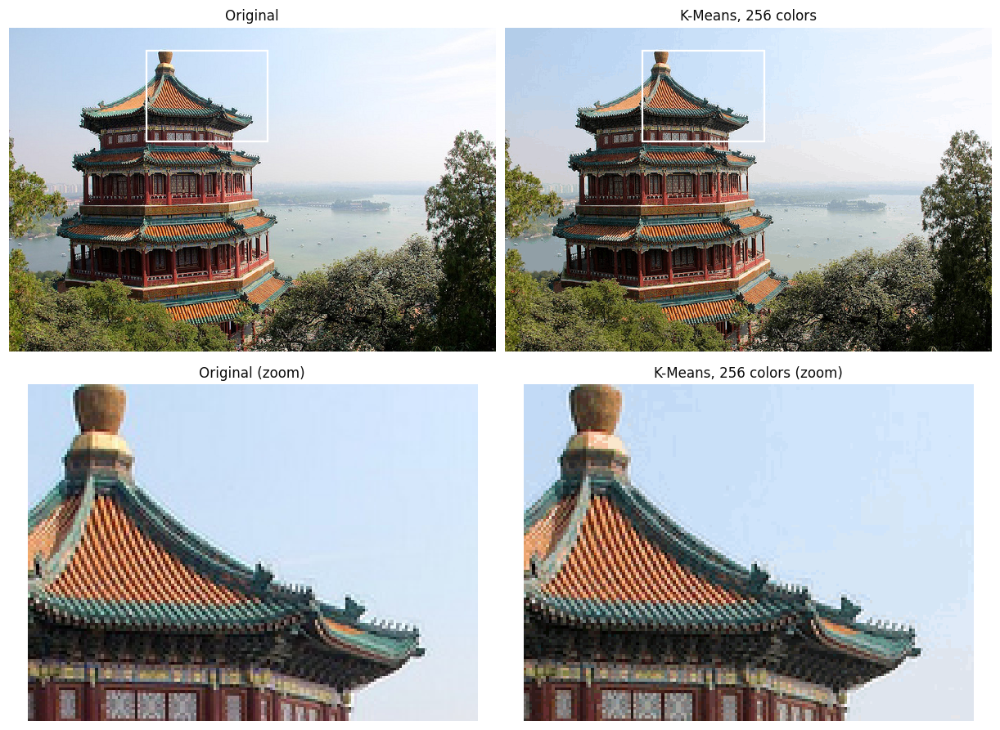

In [18]:
fig: Figure
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(11, 8),
    layout="constrained",
)
for column, (title, picture) in enumerate(
    {"Original": image, "K-Means, 256 colors": kmeans_image}.items()
):
    show(ax=axes[0, column], picture=picture, title=title)
    axes[0, column].add_patch(
        Rectangle(
            xy=(CROP_COLS.start, CROP_ROWS.start),
            width=CROP_COLS.stop - CROP_COLS.start,
            height=CROP_ROWS.stop - CROP_ROWS.start,
            fill=False,
            edgecolor="white",
            linewidth=1.5,
        ),
    )
    show(
        ax=axes[1, column],
        picture=picture[CROP_ROWS, CROP_COLS],
        title=f"{title} (zoom)",
    )
plt.show()

調色盤由暗到亮排成 16×16 的格子。

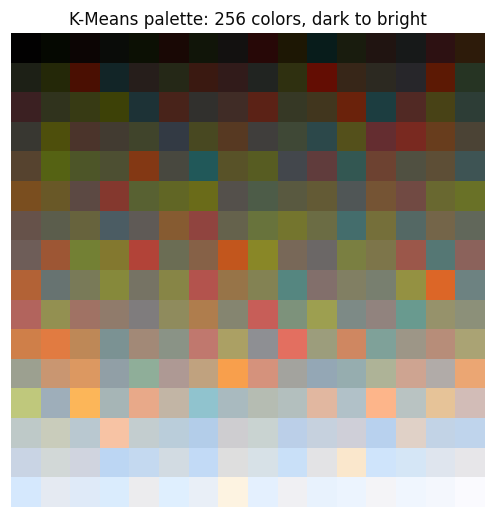

In [19]:
by_brightness: IntArray = np.argsort(a=kmeans_palette.mean(axis=1))
fig, ax = plt.subplots(figsize=(4.6, 4.6), layout="constrained")
show(
    ax=ax,
    picture=kmeans_palette[by_brightness].reshape(16, 16, 3),
    title="K-Means palette: 256 colors, dark to bright",
)
plt.show()

### A2. 比較分群方法

每種方法用 10,000 個隨機像素 fit，`AgglomerativeClustering` 用 5,000 個。名稱帶 all pixels 的兩列用全部像素，當作對照。

均勻調色盤把 R、G、B 切成等距的階數，K = 256 是 8 × 8 × 4 階，K = 16 是 2 × 4 × 2 階。隨機調色盤是隨機挑 K 個像素的顏色。

Time 是選調色盤加上指派全部像素的秒數。MSE 是均方誤差，$\mathrm{PSNR} = 10\log_{10}(1/\mathrm{MSE})$，PSNR 越大越好。

In [20]:
def uniform_palette(n_colors: int) -> FloatArray:
    """Evenly spaced RGB grid for a power-of-two color count: 256 -> 8 x 8 x 4, 16 -> 2 x 4 x 2."""
    n_bits: int = int(np.log2(n_colors))
    bits_per_channel: tuple[int, int, int] = (
        (n_bits + 1) // 3,
        (n_bits + 2) // 3,
        n_bits // 3,
    )  # R, G, B
    centers: list[FloatArray] = [
        (np.arange(2**bits) + 0.5) / 2**bits for bits in bits_per_channel
    ]
    return np.stack(arrays=np.meshgrid(*centers, indexing="ij"), axis=-1).reshape(-1, 3)


def palette_builders(n_colors: int) -> dict[str, tuple[int, Callable[[], FloatArray]]]:
    """Map each method name to (pixels it fits on, function that returns its palette)."""
    k: int = n_colors
    clusterers: dict[str, tuple[FloatArray, Clusterer]] = {
        "KMeans": (sample, KMeans(n_clusters=k, random_state=SEED)),
        "MiniBatchKMeans": (sample, MiniBatchKMeans(n_clusters=k, random_state=SEED)),
        "Agglomerative (ward)": (
            sample_agglomerative,
            AgglomerativeClustering(n_clusters=k, linkage="ward"),
        ),
        "Agglomerative (single)": (
            sample_agglomerative,
            AgglomerativeClustering(n_clusters=k, linkage="single"),
        ),
        "BisectingKMeans": (sample, BisectingKMeans(n_clusters=k, random_state=SEED)),
        # Birch defaults to threshold=0.5, which is wider than the whole [0, 1] color cube.
        "Birch": (sample, Birch(n_clusters=k, threshold=0.01)),
        "GaussianMixture": (sample, GaussianMixture(n_components=k, random_state=SEED)),
        "KMeans (all pixels)": (pixels, KMeans(n_clusters=k, random_state=SEED)),
        "MiniBatchKMeans (all pixels)": (
            pixels,
            MiniBatchKMeans(n_clusters=k, random_state=SEED),
        ),
    }
    builders: dict[str, tuple[int, Callable[[], FloatArray]]] = {
        name: (
            len(fit_pixels),
            partial(cluster_palette, sample=fit_pixels, estimator=estimator),
        )
        for name, (fit_pixels, estimator) in clusterers.items()
    }
    builders["Uniform palette"] = (0, partial(uniform_palette, n_colors=k))
    builders["Random palette"] = (
        k,
        partial(rng.choice, a=pixels, size=k, replace=False),
    )
    return builders


def run_method(
    n_fit: int, build_palette: Callable[[], FloatArray]
) -> tuple[dict[str, float], FloatArray]:
    """Time palette fitting plus pixel assignment, then score the quantized image."""
    start: float = time.perf_counter()
    palette: FloatArray = build_palette()
    nearest: IntArray = pairwise_distances_argmin(X=pixels, Y=palette)
    seconds: float = time.perf_counter() - start
    quantized: FloatArray = palette[nearest]
    mse: float = float(np.mean((quantized - pixels) ** 2))
    scores: dict[str, float] = {
        "Sample size": n_fit,
        "Time (s)": seconds,
        "MSE": mse,
        "PSNR (dB)": float(10 * np.log10(1 / mse)),
        "Colors used": len(np.unique(ar=nearest)),
    }
    return scores, quantized.reshape(image.shape)


K_COMPARE: tuple[int, int] = (256, 16)
tables: dict[int, pd.DataFrame] = {}
quantized_images: dict[int, dict[str, FloatArray]] = {}
for k in K_COMPARE:
    scores: dict[str, dict[str, float]] = {}
    quantized_images[k] = {}
    for name, (n_fit, build_palette) in palette_builders(n_colors=k).items():
        scores[name], quantized_images[k][name] = run_method(
            n_fit=n_fit, build_palette=build_palette
        )
    tables[k] = pd.DataFrame.from_dict(data=scores, orient="index").rename_axis(
        index="Method"
    )
    display(
        tables[k]
        .style.set_caption(
            caption=f"K = {k}: palette methods on china.jpg, evaluated on all {len(pixels):,} pixels"
        )
        .format(
            formatter={
                "Sample size": "{:,.0f}",
                "Time (s)": "{:.2f}",
                "MSE": "{:.6f}",
                "PSNR (dB)": "{:.2f}",
                "Colors used": "{:.0f}",
            },
        ),
    )

,Sample size,Time (s),MSE,PSNR (dB),Colors used
Method,,,,,
KMeans,"10,000",0.08,0.000244,36.13,256
MiniBatchKMeans,"10,000",0.06,0.000256,35.92,256
Agglomerative (ward),"5,000",0.43,0.000253,35.97,256
Agglomerative (single),"5,000",0.09,0.003159,25.00,256
BisectingKMeans,"10,000",0.11,0.000258,35.88,256
Birch,"10,000",0.22,0.000301,35.22,256
GaussianMixture,"10,000",15.27,0.000270,35.69,256
KMeans (all pixels),"273,280",4.10,0.000219,36.59,256
MiniBatchKMeans (all pixels),"273,280",0.41,0.000234,36.30,256


,Sample size,Time (s),MSE,PSNR (dB),Colors used
Method,,,,,
KMeans,"10,000",0.02,0.001829,27.38,16
MiniBatchKMeans,"10,000",0.01,0.001847,27.34,16
Agglomerative (ward),"5,000",0.40,0.001861,27.30,16
Agglomerative (single),"5,000",0.07,0.027566,15.60,16
BisectingKMeans,"10,000",0.02,0.001851,27.33,16
Birch,"10,000",0.19,0.002225,26.53,16
GaussianMixture,"10,000",0.23,0.002051,26.88,16
KMeans (all pixels),"273,280",0.23,0.001759,27.55,16
MiniBatchKMeans (all pixels),"273,280",0.10,0.001792,27.47,16


每種方法放大同一個區域，標題第二行是整張圖的 PSNR。

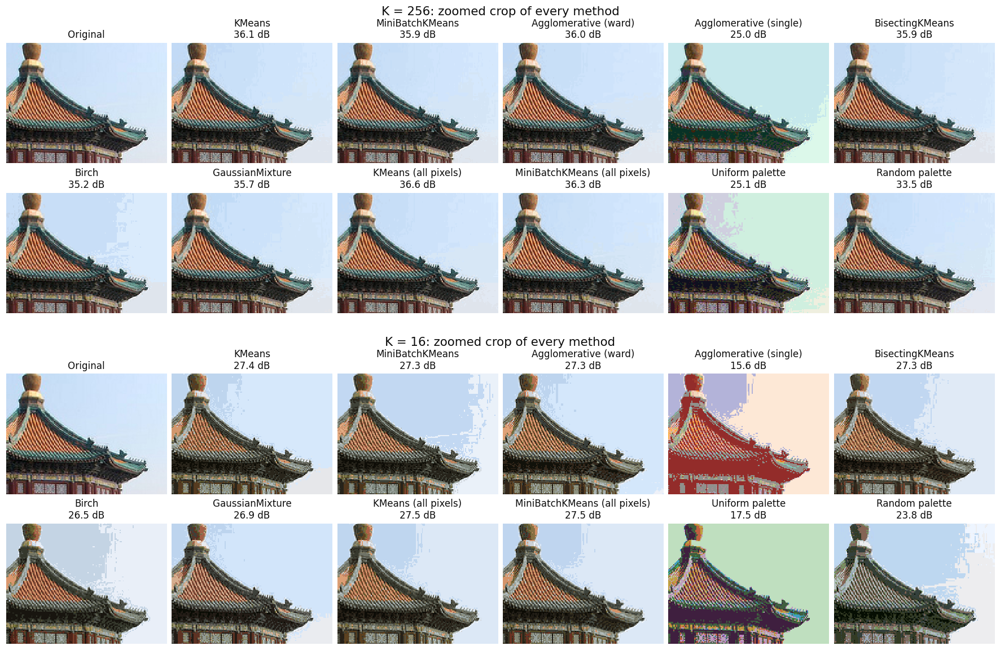

In [21]:
fig = plt.figure(figsize=(16, 10.4), layout="constrained")
for subfigure, k in zip(fig.subfigures(nrows=2, hspace=0.05), K_COMPARE, strict=True):
    subfigure.suptitle(
        t=f"K = {k}: zoomed crop of every method", fontsize=14, color=INK
    )
    panels: dict[str, FloatArray] = {"Original": image} | quantized_images[k]
    for ax, (name, picture) in zip(
        subfigure.subplots(nrows=2, ncols=6).flat, panels.items(), strict=True
    ):
        score: str = (
            "" if name == "Original" else f"\n{tables[k].loc[name, 'PSNR (dB)']:.1f} dB"
        )
        show(ax=ax, picture=picture[CROP_ROWS, CROP_COLS], title=name + score)
plt.show()

差異圖是 |原圖 − 量化結果| 對 R、G、B 取平均。同一列共用色階。

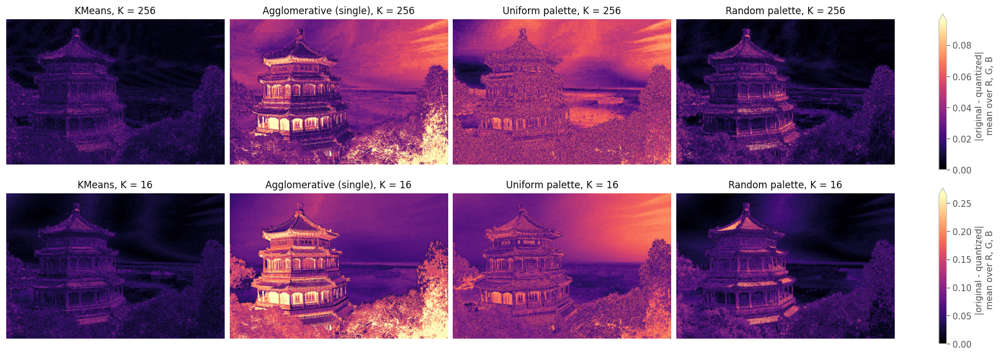

In [22]:
DIFFERENCE_METHODS: list[str] = [
    "KMeans",
    "Agglomerative (single)",
    "Uniform palette",
    "Random palette",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(16, 5.6),
    layout="constrained",
)
for row, k in enumerate(K_COMPARE):
    errors: dict[str, FloatArray] = {
        name: np.abs(image - quantized_images[k][name]).mean(axis=2)
        for name in DIFFERENCE_METHODS
    }
    # Clip the scale at the 99th percentile so a few extreme pixels do not darken everything else.
    scale_max: float = float(
        np.percentile(a=np.stack(arrays=list(errors.values())), q=99)
    )
    for ax, (name, error) in zip(axes[row], errors.items(), strict=True):
        heatmap = ax.imshow(
            X=error,
            cmap="magma",
            vmin=0.0,
            vmax=scale_max,
        )
        ax.set_title(label=f"{name}, K = {k}")
        ax.set_axis_off()
    fig.colorbar(
        mappable=heatmap,
        ax=axes[row],
        label="|original - quantized|\nmean over R, G, B",
        extend="max",
    )
plt.show()

### A3. 視覺化分群的效果

隨機取 2,000 個像素放進 RGB 空間，塗上它被指派到的調色盤顏色。兩種方法都是 K = 16。

KMeans: the most used color covers 13.6% of all pixels
Agglomerative (single): the most used color covers 34.6% of all pixels


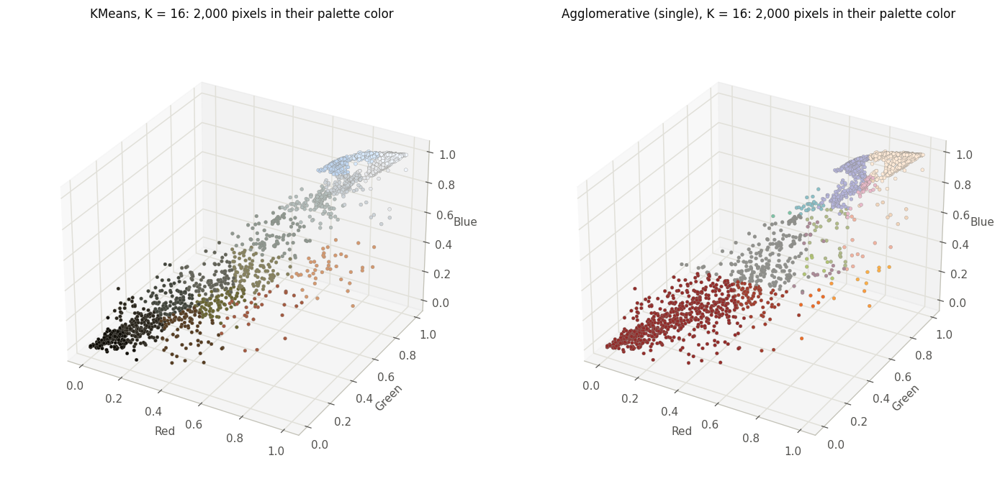

In [23]:
SCATTER_K: int = 16
SCATTER_METHODS: list[str] = ["KMeans", "Agglomerative (single)"]

shown: IntArray = rng.choice(a=len(pixels), size=2_000, replace=False)
fig, axes = plt.subplots(
    ncols=2,
    figsize=(13, 6.2),
    subplot_kw={"projection": "3d"},
    layout="constrained",
)
for ax, name in zip(axes, SCATTER_METHODS, strict=True):
    quantized_pixels: FloatArray = quantized_images[SCATTER_K][name].reshape(-1, 3)
    ax.scatter(
        xs=pixels[shown, 0],
        ys=pixels[shown, 1],
        zs=pixels[shown, 2],
        c=quantized_pixels[shown],
        s=10,
        edgecolors="#898781",
        linewidths=0.2,
        depthshade=False,
    )
    ax.set(
        xlabel="Red",
        ylabel="Green",
        zlabel="Blue",
        title=f"{name}, K = {SCATTER_K}: 2,000 pixels in their palette color",
    )
    ax.set_box_aspect(aspect=None, zoom=0.88)
    _, color_counts = np.unique(ar=quantized_pixels, axis=0, return_counts=True)
    print(
        f"{name}: the most used color covers {color_counts.max() / len(pixels):.1%} of all pixels"
    )
plt.show()

`KMeans` 把像素切成 16 塊，暗綠、紅褐、淺藍各有自己的顏色。

single linkage 只看兩群之間最近的一對點，相鄰的點一路串起來。5,000 個樣本有 4,971 個併成同一群，其餘 15 群各只有 1 到 9 個像素。

所以調色盤只有一個灰色代表整張圖，其他 15 色都來自落單的像素。暗部的像素離灰色太遠，全部被分到一個只由 3 個像素算出來的暗紅色。

K 從 2 每次加倍到 256，兩軸都是對數刻度。曲線越低，誤差越小。

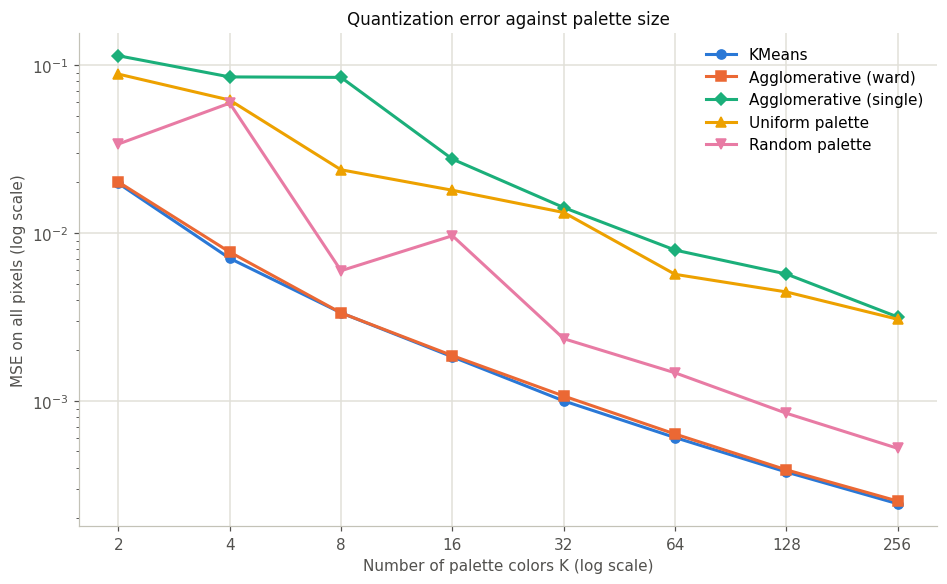

In [24]:
K_VALUES: list[int] = [2**power for power in range(1, 9)]
CURVE_METHODS: list[str] = [
    "KMeans",
    "Agglomerative (ward)",
    "Agglomerative (single)",
    "Uniform palette",
    "Random palette",
]

mse_curves: dict[str, list[float]] = {name: [] for name in CURVE_METHODS}
for k in K_VALUES:
    builders: dict[str, tuple[int, Callable[[], FloatArray]]] = palette_builders(
        n_colors=k
    )
    for name in CURVE_METHODS:
        n_fit, build_palette = builders[name]
        scores_at_k, _ = run_method(n_fit=n_fit, build_palette=build_palette)
        mse_curves[name].append(scores_at_k["MSE"])

fig, ax = plt.subplots(figsize=(8.5, 5.2), layout="constrained")
for (name, curve), color, marker in zip(
    mse_curves.items(), SERIES_COLORS, "osD^v", strict=True
):
    ax.plot(
        K_VALUES,
        curve,
        label=name,
        color=color,
        marker=marker,
        markersize=6,
        linewidth=2,
    )
ax.set_xscale(value="log", base=2)
ax.set_yscale(value="log")
ax.set_xticks(ticks=K_VALUES, labels=[str(k) for k in K_VALUES])
ax.set(
    xlabel="Number of palette colors K (log scale)",
    ylabel="MSE on all pixels (log scale)",
    title="Quantization error against palette size",
)
ax.grid(visible=True, which="major")
ax.legend(frameon=False)
plt.show()

### A4. 討論

**推薦 `KMeans` 加取樣：又快又好**

用 10,000 個樣本不到 0.1 秒，K = 256 的 PSNR 是 36.13 dB。改用全部像素只多 0.46 dB，時間卻要約 5 秒。

品質前幾名很接近，`MiniBatchKMeans`、ward、`BisectingKMeans` 都在 35.9 dB 上下。所以要看速度和記憶體。

- **ward**：品質和 `KMeans` 相同，但記憶體隨樣本數的平方成長，只能跑在樣本上。
- **`GaussianMixture`**：約 15 秒，是最慢的，品質還略輸。它多算了每群的形狀，調色盤只用得到平均色。
- **`MiniBatchKMeans`**：取樣後沒有比 `KMeans` 快。用全部像素才有差，約 0.3 秒對 5 秒。

**表現不好的方法：single linkage**

K = 256 只有 25.0 dB，比隨機調色盤的 33.5 dB 還差。

它把相鄰的點一路串起來，5,000 個樣本有 4,577 個併成同一群。剩下的調色盤顏色都浪費在落單的像素上。

**多測一件事：色彩量化能省多少空間**

想測的原因是色彩量化本身就是一種壓縮。原圖每個像素要存 R、G、B 三個數字。量化後每個像素只要存「調色盤的第幾號」，一個數字就夠。

PSNR 只量了畫質掉多少，沒量到省了多少空間。所以把 `KMeans` 的結果實際存成 PNG，看檔案大小。

In [25]:
import io

from PIL import Image


def png_kilobytes(picture: Image.Image) -> float:
    """Size of the picture saved as a PNG at the strongest compression, in kilobytes."""
    buffer: io.BytesIO = io.BytesIO()
    picture.save(fp=buffer, format="PNG", compress_level=9)
    return buffer.tell() / 1000


def color_codes(rgb: NDArray[np.uint8]) -> NDArray[np.uint32]:
    """Pack each pixel's R, G, B bytes into one integer, 0xRRGGBB."""
    weights: NDArray[np.uint32] = np.array(object=[1 << 16, 1 << 8, 1], dtype=np.uint32)
    return rgb.astype(np.uint32) @ weights


def to_indexed(rgb: NDArray[np.uint8]) -> Image.Image:
    """Store one palette index per pixel instead of three color values."""
    codes, indices = np.unique(ar=color_codes(rgb=rgb), return_inverse=True)
    palette: NDArray[np.uint8] = np.stack(
        arrays=[(codes >> 16) & 0xFF, (codes >> 8) & 0xFF, codes & 0xFF],
        axis=1,
    ).astype(np.uint8)
    indexed: Image.Image = Image.fromarray(
        obj=indices.reshape(rgb.shape[:2]).astype(np.uint8),
    )
    indexed.putpalette(data=palette.tobytes())  # switches the image to palette mode
    return indexed


ORIGINAL_ROW: str = "Original, saved as RGB"

original_rgb: NDArray[np.uint8] = np.round(image * 255).astype(np.uint8)
png_sizes: dict[str, float] = {
    ORIGINAL_ROW: png_kilobytes(picture=Image.fromarray(obj=original_rgb)),
}
for k in K_COMPARE:
    quantized_rgb: NDArray[np.uint8] = np.round(
        quantized_images[k]["KMeans"] * 255,
    ).astype(np.uint8)
    png_sizes[f"KMeans {k} colors, saved as RGB"] = png_kilobytes(
        picture=Image.fromarray(obj=quantized_rgb),
    )
    png_sizes[f"KMeans {k} colors, saved as indexed"] = png_kilobytes(
        picture=to_indexed(rgb=quantized_rgb),
    )

png_table: pd.DataFrame = pd.DataFrame(data={"PNG size (kB)": png_sizes})
png_table["Share of original (%)"] = (
    100 * png_table["PNG size (kB)"] / png_sizes[ORIGINAL_ROW]
)
display(
    png_table.rename_axis(index="Image")
    .style.set_caption(caption="PNG file size of china.jpg before and after K-Means")
    .format(precision=1),
)

,PNG size (kB),Share of original (%)
Image,,
"Original, saved as RGB",485.8,100.0
"KMeans 256 colors, saved as RGB",385.2,79.3
"KMeans 256 colors, saved as indexed",145.8,30.0
"KMeans 16 colors, saved as RGB",130.6,26.9
"KMeans 16 colors, saved as indexed",58.4,12.0


256 色存成索引色 PNG 只有原圖的 30%，16 色只有 12%。代價是畫質，256 色幾乎看不出差別，16 色有明顯的色塊。

存檔要用索引色，也就是每個像素只存編號，才省得到空間。256 色的圖照一般 RGB 存，還有原圖的 79%。

**換一張圖再測：手繪圖會不會更適合調色盤**

想測的原因是 `china.jpg` 是照片，顏色是連續變化的。手繪圖大多是整片同色，照理說少數幾種顏色就夠用。

所以拿一張手繪圖做同樣的事：抽 10,000 個像素給 `KMeans`，再存成索引色 PNG。圖放在 GitHub，執行時直接下載。

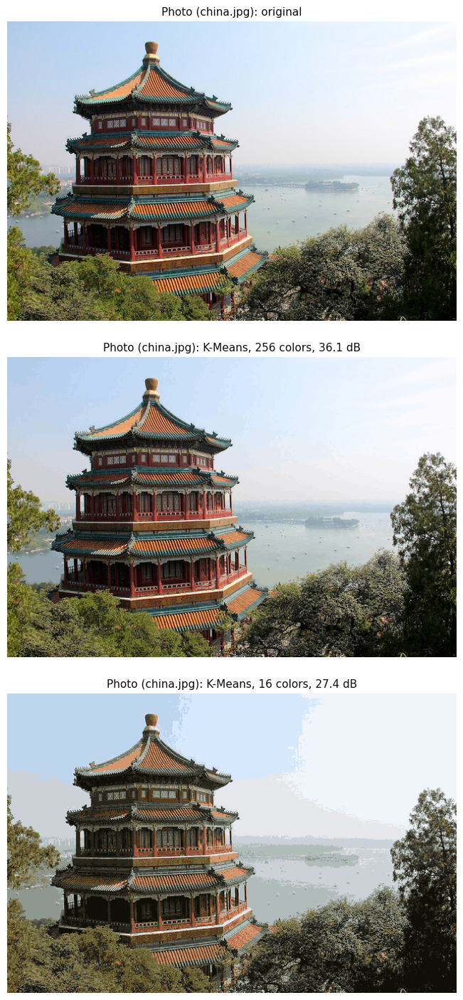

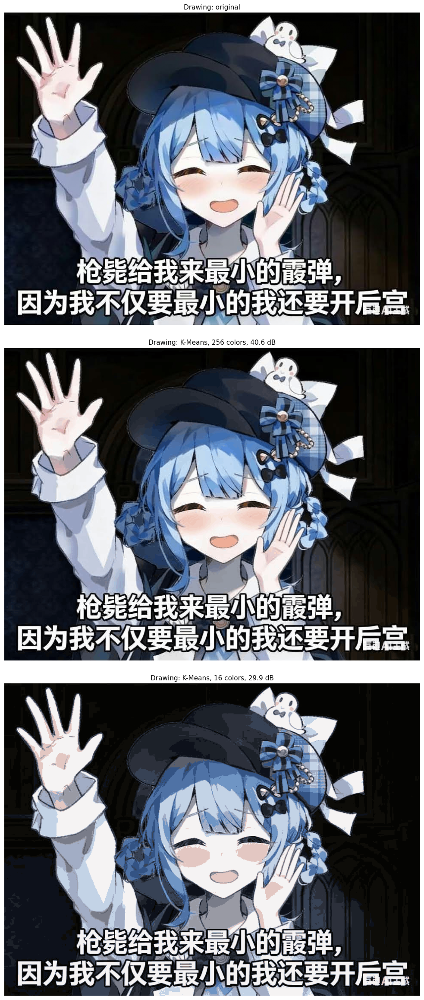

In [26]:
from urllib.request import urlopen

from pandas.io.formats.style import Styler

PANEL_MAX_PIXELS: int = 1400  # widest a comparison panel is drawn
PANEL_DPI: int = 100
DRAWING_URL: str = (
    "https://raw.githubusercontent.com/yufeng-kano/nycu-code/main/"
    "data-science-software-and-computation-experiments/hw3/data/image/"
    "sherry_love_loli.png"
)


def kmeans_quantize(picture: FloatArray, n_colors: int) -> FloatArray:
    """Fit K-Means on N_FIT sampled pixels, then recolor every pixel from its palette."""
    flat: FloatArray = picture.reshape(-1, 3)
    fit_pixels: FloatArray = np.random.default_rng(seed=SEED).choice(
        a=flat,
        size=N_FIT,
        replace=False,
    )
    palette: FloatArray = cluster_palette(
        sample=fit_pixels,
        estimator=KMeans(n_clusters=n_colors, random_state=SEED),
    )
    nearest: IntArray = pairwise_distances_argmin(X=flat, Y=palette)
    return palette[nearest].reshape(picture.shape)


def compare_storage(
    name: str,
    picture: FloatArray,
) -> dict[tuple[str, int], dict[str, float]]:
    """Quantize the picture for each K, plot the results, return quality and PNG sizes."""
    height, width, _ = picture.shape
    n_pixels: int = height * width
    rgb: NDArray[np.uint8] = np.round(picture * 255).astype(np.uint8)
    original_kb: float = png_kilobytes(picture=Image.fromarray(obj=rgb))
    # Variance of the pixel cloud along each of its three principal directions.
    axis_variances: NDArray[np.floating] = np.linalg.eigvalsh(
        a=np.cov(m=picture.reshape(-1, 3), rowvar=False),
    )
    rows: dict[tuple[str, int], dict[str, float]] = {}
    panels: dict[str, FloatArray] = {f"{name}: original": picture}
    for k in K_COMPARE:
        quantized: FloatArray = kmeans_quantize(picture=picture, n_colors=k)
        mse: float = float(np.mean((quantized - picture) ** 2))
        indexed_kb: float = png_kilobytes(
            picture=to_indexed(rgb=np.round(quantized * 255).astype(np.uint8)),
        )
        rows[(name, k)] = {
            "Pixels": n_pixels,
            "Distinct colors": len(np.unique(ar=color_codes(rgb=rgb))),
            "Main-axis variance (%)": 100 * axis_variances.max() / axis_variances.sum(),
            "PSNR (dB)": float(10 * np.log10(1 / mse)),
            "Original PNG (bytes/pixel)": 1000 * original_kb / n_pixels,
            "Indexed PNG (bytes/pixel)": 1000 * indexed_kb / n_pixels,
            "Share of original (%)": 100 * indexed_kb / original_kb,
        }
        psnr_label: str = f"{rows[(name, k)]['PSNR (dB)']:.1f} dB"
        panels[f"{name}: K-Means, {k} colors, {psnr_label}"] = quantized

    # One panel per row, drawn at the image's own resolution up to PANEL_MAX_PIXELS wide.
    panel_inches: float = min(width, PANEL_MAX_PIXELS) / PANEL_DPI
    _, axes = plt.subplots(
        nrows=len(panels),
        figsize=(panel_inches, len(panels) * (panel_inches * height / width + 0.45)),
        dpi=PANEL_DPI,
        layout="constrained",
    )
    for ax, (title, panel) in zip(axes, panels.items(), strict=True):
        ax.imshow(X=panel, interpolation="antialiased")
        ax.set_title(label=title)
        ax.set_axis_off()
    plt.show()
    return rows


def storage_table(rows: dict[tuple[str, int], dict[str, float]]) -> Styler:
    """Format the per-image, per-K results as one table."""
    table: Styler = (
        pd.DataFrame.from_dict(data=rows, orient="index")
        .rename_axis(index=["Image", "K"])
        .style.set_caption(caption="K-Means quantization: quality and PNG size")
    )
    table.format(
        formatter={
            "Pixels": "{:,.0f}",
            "Distinct colors": "{:,.0f}",
            "Main-axis variance (%)": "{:.1f}",
            "PSNR (dB)": "{:.1f}",
            "Original PNG (bytes/pixel)": "{:.2f}",
            "Indexed PNG (bytes/pixel)": "{:.2f}",
            "Share of original (%)": "{:.1f}",
        },
    )
    return table


with urlopen(url=DRAWING_URL) as response:
    drawing: FloatArray = (
        np.asarray(Image.open(fp=io.BytesIO(response.read())).convert(mode="RGB"))
        / 255.0
    )

storage_rows: dict[tuple[str, int], dict[str, float]] = {}
for name, picture in {"Photo (china.jpg)": image, "Drawing": drawing}.items():
    storage_rows |= compare_storage(name=name, picture=picture)
display(storage_table(rows=storage_rows))

同樣的顏色數，手繪圖的畫質掉得比較少。256 色是 40.6 dB，照片是 36.1 dB。16 色是 29.9 dB，照片是 27.4 dB。

檔案大小卻沒有比較省。256 色時手繪圖還剩原圖的 39%，照片是 30%。16 色時兩者都約 12%。

我猜是因為這張圖原本是 JPEG。壓縮留下的雜訊讓它有 80,846 種顏色，所以不好壓。

16 色的圖裡，臉頰的粉紅變成灰色。粉紅色的像素很少，分群時分不到自己的調色盤顏色。

**第三張圖：可是我還是覺得怪怪的**

上面把手繪圖省得少怪給 JPEG 雜訊，但那只是猜的，沒有驗證。所以再找一張原生 PNG 來測，它從頭到尾沒有經過 JPEG。

這張是 **《魔法少女的魔女審判》的「焗雪莉」CG**。它的顏色也比前兩張豐富，同時有紫、橘、藍、紅。

為了避免不必要的紛爭，不提供原圖，只提供下面這格的輸出。這一格要有原圖才能重跑。

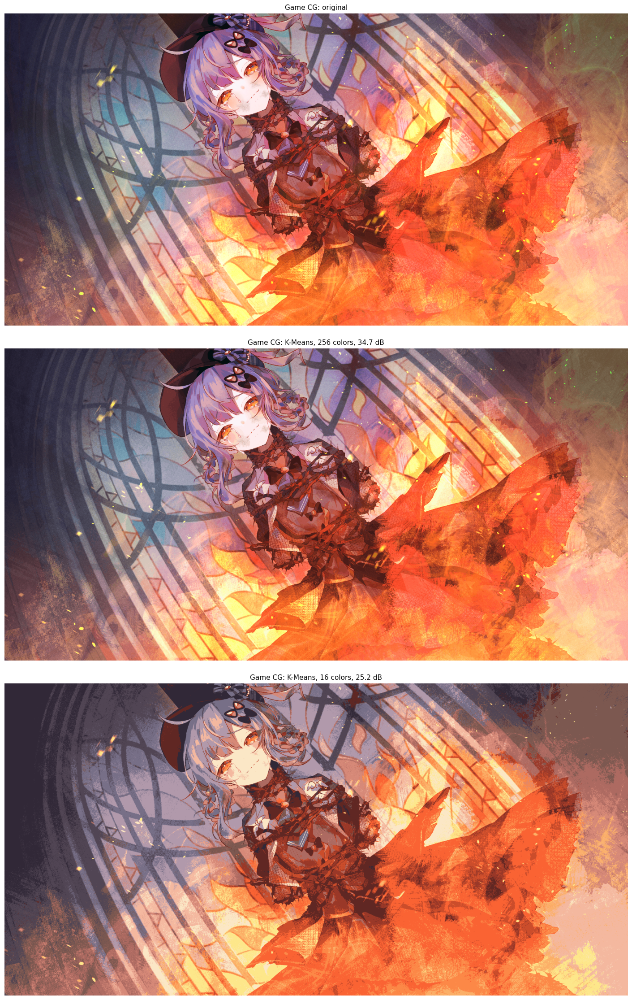

In [27]:
from pathlib import Path

CG_PATH: Path = Path("data/image/焗雪莉.png")  # local only: not committed to the repo

cg: FloatArray = np.asarray(Image.open(fp=CG_PATH).convert(mode="RGB")) / 255.0
storage_rows |= compare_storage(name="Game CG", picture=cg)
display(storage_table(rows=storage_rows))

結果推翻了前面的猜測。這張圖沒有 JPEG 雜訊，256 色卻還剩原圖的 41%，省得比手繪圖更少。所以問題不在 JPEG。

回頭看表格的 bytes/pixel 欄，也就是平均每個像素佔幾個 byte。照片的原圖要 1.78，手繪圖和 CG 只要 1.00 和 1.10。這兩張圖有大片相近的顏色，PNG 本來就壓得好，能再省的比例自然少。

另一個沒想到的是畫質。這張圖只有 20,258 種顏色，是三張裡最少的，256 色的 PSNR 卻最低，只有 34.7 dB。

原因在 Main-axis variance 欄，它是顏色變化落在同一條線上的比例。前兩張都超過 97%，顏色幾乎只是由暗到亮。這張只有 74%，顏色往各個方向散開，256 個顏色不夠分。

16 色時彩色玻璃的藍綠色不見了，變成灰紫色。這和手繪圖的粉紅臉頰是同一個現象。

**再補一個：我之前報告過的 e-means**

想測的原因是好奇。e-means 是 2026 年 11 月的論文，它說只要十分之一的 epoch 就能追上 K-Means。epoch 是把全部資料看過一遍。

它是為大資料設計的，所以這次不取樣，直接用照片的全部 273,280 個像素。對照組是同樣用全部像素的 `KMeans` 和 `MiniBatchKMeans`。e-means 用 Faiss 內建的官方實作。

In [28]:
import os

import faiss
from faiss.contrib.e_means import NumpyEmeans

# With all 20 threads the timing on this machine jumped between 0.3 s and 14 s.
faiss.omp_set_num_threads(min(4, os.cpu_count() or 1))

EMEANS_EPOCHS: tuple[int, ...] = (1, 5, 25)

emeans_rows: dict[tuple[int, str], dict[str, float]] = {}
for k in K_COMPARE:
    baselines: dict[str, KMeans | MiniBatchKMeans] = {
        "KMeans, k-means++ start": KMeans(n_clusters=k, random_state=SEED),
        "KMeans, random start": KMeans(
            n_clusters=k,
            init="random",
            random_state=SEED,
        ),
        "MiniBatchKMeans": MiniBatchKMeans(n_clusters=k, random_state=SEED),
    }
    for name, baseline in baselines.items():
        method_scores, _ = run_method(
            n_fit=len(pixels),
            build_palette=lambda baseline=baseline: (
                baseline.fit(
                    X=pixels,
                ).cluster_centers_
            ),
        )
        emeans_rows[(k, name)] = {"Epochs": baseline.n_iter_} | method_scores
    for n_epochs in EMEANS_EPOCHS:
        emeans: NumpyEmeans = NumpyEmeans(d=3, k=k, nepochs=n_epochs, seed=SEED)
        method_scores, _ = run_method(
            n_fit=len(pixels),
            build_palette=lambda emeans=emeans: emeans.train(
                x=pixels.astype(np.float32),
            )[0].astype(np.float64),
        )
        emeans_rows[(k, f"e-means, epochs={n_epochs}")] = {
            "Epochs": n_epochs,
        } | method_scores

display(
    pd.DataFrame.from_dict(data=emeans_rows, orient="index")
    .rename_axis(index=["K", "Method"])[["Epochs", "Time (s)", "PSNR (dB)"]]
    .style.set_caption(caption=f"Fitting on all {len(pixels):,} pixels of china.jpg")
    .format(
        formatter={"Epochs": "{:.0f}", "Time (s)": "{:.2f}", "PSNR (dB)": "{:.2f}"}
    ),
)

速度和論文說的一樣。256 色時 e-means 跑 5 個 epoch 約 0.3 秒，`KMeans` 跑了 47 個 epoch，約 4 秒。

畫質卻沒有追上。e-means 跑 5 個 epoch 是 35.94 dB，跑到 25 個也只有 35.98 dB，`KMeans` 是 36.59 dB。

我覺得怪怪的，所以多測了一組隨機起始的 `KMeans`。scikit-learn 的 `KMeans` 預設用 k-means++ 挑起始中心，e-means 是隨機挑。

換成隨機起始後，`KMeans` 跑了 88 個 epoch 也只有 36.07 dB，和 e-means 只差 0.09 dB。所以差距大部分來自起始中心，不是 e-means 本身比較差。

論文自己也寫了限制。它的 batch size 和步伐公式是用高維資料擬合的，低維的小資料不是最佳。我們的顏色只有 3 維。

這份作業我還是選 `MiniBatchKMeans`。它和 e-means 一樣快，畫質是 36.27 dB，比較高。16 色時這幾種方法都在 27.4 到 27.6 dB，分不出高下。

## Part B：用回歸還原 Dithering

**Dithering 是什麼：只用黑點和白點，靠白點的密度表現灰階**

一塊區域裡白點佔 30%，遠看就是 30% 亮的灰。

**算一次：處理一個原值 0.6 的像素**

- 0.6 ≥ 0.5，新值設為 1，畫成白點
- 誤差 = 0.6 − 1 = −0.4，這個點畫得太亮
- 把 −0.4 分給還沒處理的鄰居：右邊拿 7/16 是 −0.175，左下拿 3/16 是 −0.075，下面拿 5/16 是 −0.125，右下拿 1/16 是 −0.025

鄰居被調暗後比較容易變成黑點，平均起來亮度就對了。

**Part B 要做的事：從黑白點猜回原本的灰階**

輸入是某個像素周圍 k × k 的黑白點，輸出是該像素原本的灰階值。輸出是連續的數字，所以是回歸問題。

### B1. 實作 Floyd–Steinberg dithering

由左到右、由上到下掃描。影像的左、右、下各多補一排 0 來接流出邊界的誤差，最後切掉。

下圖第三列是橘框區域的放大，可以看到一顆一顆的黑白點。

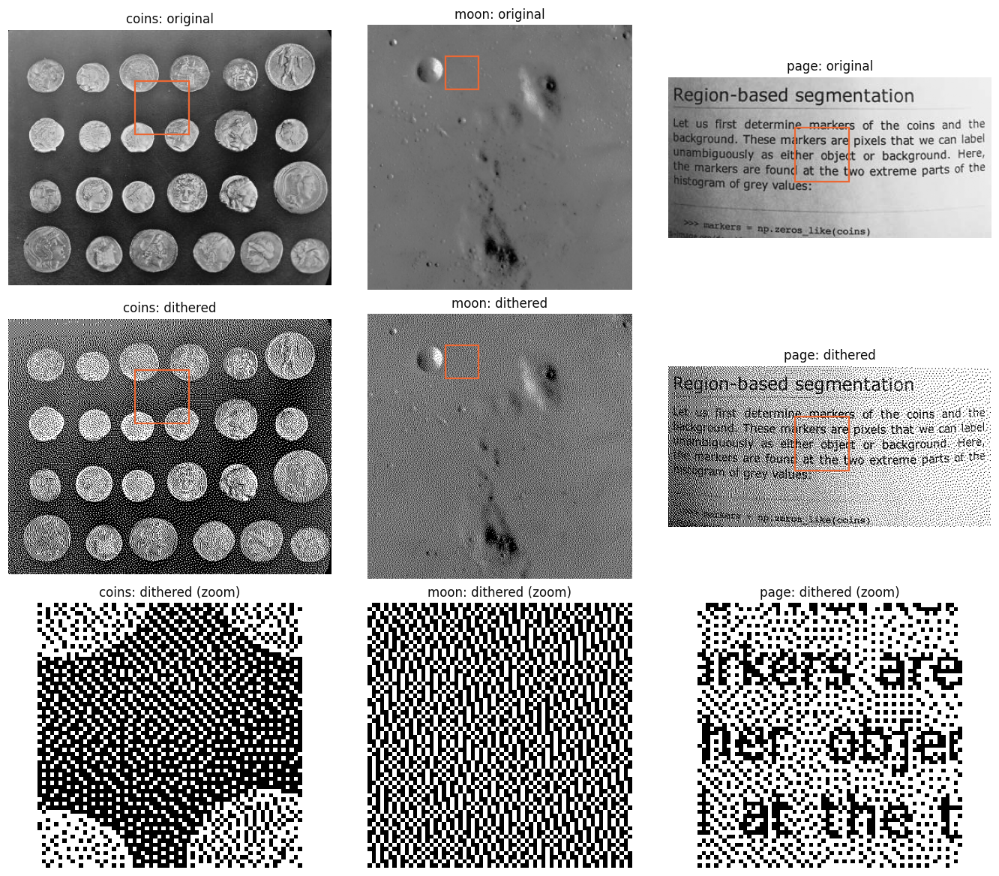

In [29]:
from matplotlib.colors import LinearSegmentedColormap
from numpy.lib.stride_tricks import sliding_window_view
from scipy.ndimage import gaussian_filter
from skimage import data
from skimage.color import rgb2gray
from skimage.transform import resize
from skimage.util import img_as_float
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

DEMO_ROWS: slice = slice(60, 124)  # zoom region of the dithering demo
DEMO_COLS: slice = slice(150, 214)


def fs_dither(img: FloatArray) -> FloatArray:
    """Floyd-Steinberg dithering: turn a grayscale image in [0, 1] into black and white."""
    height, width = img.shape
    # A spare column on each side and a spare row below catch the error that leaves the image.
    work: FloatArray = np.pad(array=img.astype(np.float64), pad_width=((0, 1), (1, 1)))
    for row in range(height):
        for column in range(1, width + 1):
            old: float = work[row, column]
            new: float = 1.0 if old >= 0.5 else 0.0
            error: float = old - new
            work[row, column] = new
            work[row, column + 1] += error * 7 / 16  # right
            work[row + 1, column - 1] += error * 3 / 16  # lower left
            work[row + 1, column] += error * 5 / 16  # below
            work[row + 1, column + 1] += error * 1 / 16  # lower right
    return work[:height, 1 : width + 1]


def show_gray(ax: Axes, picture: FloatArray, title: str) -> None:
    """Draw a grayscale image with 0 as black and 1 as white."""
    ax.imshow(X=picture, cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(label=title)
    ax.set_axis_off()


def outline(ax: Axes, rows: slice, cols: slice) -> None:
    """Mark the region that the zoomed panel shows."""
    ax.add_patch(
        Rectangle(
            xy=(cols.start, rows.start),
            width=cols.stop - cols.start,
            height=rows.stop - rows.start,
            fill=False,
            edgecolor=SERIES_COLORS[1],
            linewidth=1.5,
        ),
    )


demo_images: dict[str, FloatArray] = {
    "coins": data.coins() / 255.0,
    "moon": data.moon() / 255.0,
    "page": data.page() / 255.0,
}
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 10.5), layout="constrained")
for column, (name, gray) in enumerate(demo_images.items()):
    dithered: FloatArray = fs_dither(img=gray)
    show_gray(ax=axes[0, column], picture=gray, title=f"{name}: original")
    show_gray(ax=axes[1, column], picture=dithered, title=f"{name}: dithered")
    show_gray(
        ax=axes[2, column],
        picture=dithered[DEMO_ROWS, DEMO_COLS],
        title=f"{name}: dithered (zoom)",
    )
    for ax in axes[:2, column]:
        outline(ax=ax, rows=DEMO_ROWS, cols=DEMO_COLS)
plt.show()

### B2. 資料集

9 張訓練影像、2 張測試影像，都轉成灰階、縮成 256 × 256，再做 dithering。

**為什麼不能在訓練像素上測試：** 模型已經看過這些像素和答案，分數量到的是記憶，不是還原新影像的能力。B6 最後有實測。

下表順便檢查 dithering 有沒有做對：白點的比例應該等於原圖的平均灰階。

In [30]:
TRAIN_NAMES: tuple[str, ...] = (
    "coins",
    "moon",
    "chelsea",
    "coffee",
    "rocket",
    "brick",
    "grass",
    "gravel",
    "page",
)
TEST_NAMES: tuple[str, ...] = ("camera", "astronaut")
IMAGE_SIZE: int = 256


def load_gray(name: str) -> FloatArray:
    """Load a scikit-image sample as grayscale in [0, 1], resized to a square."""
    raw: NDArray[np.uint8] = getattr(data, name)()
    gray: FloatArray = rgb2gray(raw) if raw.ndim == 3 else img_as_float(raw)
    return resize(
        image=gray,
        output_shape=(IMAGE_SIZE, IMAGE_SIZE),
        anti_aliasing=True,
    )


grays: dict[str, FloatArray] = {
    name: load_gray(name=name) for name in TRAIN_NAMES + TEST_NAMES
}
dithers: dict[str, FloatArray] = {
    name: fs_dither(img=gray) for name, gray in grays.items()
}

display(
    pd.DataFrame.from_dict(
        data={
            name: {
                "Split": "train" if name in TRAIN_NAMES else "test",
                "Mean gray level": grays[name].mean(),
                "White pixels after dithering (share)": dithers[name].mean(),
            }
            for name in grays
        },
        orient="index",
    )
    .rename_axis(index="Image")
    .style.set_caption(caption=f"All images are {IMAGE_SIZE} x {IMAGE_SIZE} pixels")
    .format(precision=3),
)

,Split,Mean gray level,White pixels after dithering (share)
Image,,,
coins,train,0.380,0.379
moon,train,0.440,0.440
chelsea,train,0.460,0.460
coffee,train,0.387,0.387
rocket,train,0.239,0.238
brick,train,0.437,0.437
grass,train,0.464,0.464
gravel,train,0.496,0.496
page,train,0.673,0.673


### B3. 特徵與目標

- **區塊大小**：7 × 7 和 11 × 11，也就是 49 個和 121 個特徵。邊界用鏡射補齊。
- **訓練樣本**：從 9 張訓練影像的 589,824 個像素隨機抽 60,000 個。所有模型、兩種區塊大小都用同一組像素。
- **測試**：兩張測試影像的全部 131,072 個像素。

In [31]:
PATCH_SIZES: tuple[int, ...] = (7, 11)
N_TRAIN: int = 60_000

Features: TypeAlias = NDArray[np.float32]


def patch_features(dithered: FloatArray, size: int) -> Features:
    """One row per pixel: the size x size dithered patch centered on it, flattened."""
    padded: FloatArray = np.pad(array=dithered, pad_width=size // 2, mode="reflect")
    return (
        sliding_window_view(x=padded, window_shape=(size, size))
        .reshape(-1, size * size)
        .astype(np.float32)
    )


def sample_patches(
    dithered: dict[str, FloatArray],
    names: tuple[str, ...],
    size: int,
    skip: int = 0,
) -> tuple[Features, FloatArray]:
    """Patches and gray targets of N_TRAIN random pixels from the named images.

    The pixels are shuffled with a fixed seed, so every patch size gets the same ones.
    `skip` passes over that many shuffled pixels first, which gives a disjoint sample.
    """
    features: Features = np.concatenate(
        [patch_features(dithered=dithered[name], size=size) for name in names]
    )
    targets: FloatArray = np.concatenate([grays[name].ravel() for name in names])
    order: IntArray = np.random.default_rng(seed=SEED).permutation(len(targets))
    chosen: IntArray = order[skip : skip + N_TRAIN]
    return features[chosen], targets[chosen]


train_sets: dict[int, tuple[Features, FloatArray]] = {
    size: sample_patches(dithered=dithers, names=TRAIN_NAMES, size=size)
    for size in PATCH_SIZES
}
test_features: dict[int, dict[str, Features]] = {
    size: {
        name: patch_features(dithered=dithers[name], size=size) for name in TEST_NAMES
    }
    for size in PATCH_SIZES
}
for size in PATCH_SIZES:
    print(
        f"{size} x {size} patches: train features {train_sets[size][0].shape}, "
        f"test features per image {test_features[size]['camera'].shape}"
    )

7 x 7 patches: train features (60000, 49), test features per image (65536, 49)
11 x 11 patches: train features (60000, 121), test features per image (65536, 121)


### B4. Baseline：高斯模糊

模糊就是把附近的黑白點平均起來。σ 越大，平均的範圍越大。

在 9 張訓練影像上試 σ = 0.4 到 3.0，選 PSNR 最高的，再拿去測試影像算分數。

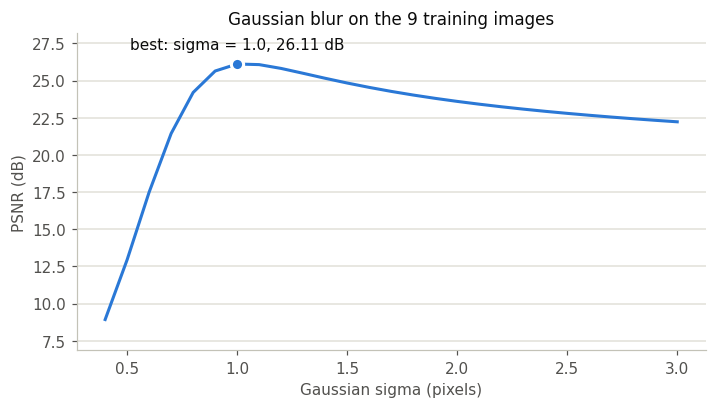

,camera PSNR (dB),astronaut PSNR (dB)
Baseline,,
Gaussian blur (sigma = 1.0),27.12,26.62


In [32]:
SIGMAS: NDArray[np.floating] = np.round(
    np.arange(start=0.4, stop=3.01, step=0.1), decimals=1
)
NO_PATCH: str = "none"  # the blur baseline has no patch size


def psnr(reference: FloatArray, estimate: FloatArray) -> float:
    """Peak signal-to-noise ratio in dB for values in [0, 1]."""
    return float(10 * np.log10(1 / np.mean((reference - estimate) ** 2)))


def test_psnr(restored: dict[str, FloatArray]) -> dict[str, float]:
    """PSNR of each restored test image against its original."""
    return {
        f"{name} PSNR (dB)": psnr(reference=grays[name], estimate=restored[name])
        for name in TEST_NAMES
    }


train_grays: FloatArray = np.stack(arrays=[grays[name] for name in TRAIN_NAMES])
search_start: float = time.perf_counter()
train_blur_psnr: list[float] = [
    psnr(
        reference=train_grays,
        estimate=np.stack(
            arrays=[
                gaussian_filter(input=dithers[name], sigma=sigma)
                for name in TRAIN_NAMES
            ],
        ),
    )
    for sigma in SIGMAS
]
best_sigma: float = float(SIGMAS[int(np.argmax(a=train_blur_psnr))])
blur_search_seconds: float = time.perf_counter() - search_start

blur_start: float = time.perf_counter()
blurred: dict[str, FloatArray] = {
    name: gaussian_filter(input=dithers[name], sigma=best_sigma) for name in TEST_NAMES
}
blur_seconds: float = time.perf_counter() - blur_start

BLUR: str = f"Gaussian blur (sigma = {best_sigma})"
blur_row: dict[str, float] = {
    "Train time (s)": blur_search_seconds,
    "Predict time (s)": blur_seconds,
} | test_psnr(restored=blurred)

fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
ax.plot(SIGMAS, train_blur_psnr, color=SERIES_COLORS[0], linewidth=2)
ax.scatter(
    x=[best_sigma],
    y=[max(train_blur_psnr)],
    s=64,
    color=SERIES_COLORS[0],
    edgecolors="white",
    linewidths=2,
    zorder=3,
)
ax.annotate(
    text=f"best: sigma = {best_sigma}, {max(train_blur_psnr):.2f} dB",
    xy=(best_sigma, max(train_blur_psnr)),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    color=INK,
)
ax.margins(y=0.12)
ax.set_title(label="Gaussian blur on the 9 training images")
ax.set_xlabel(xlabel="Gaussian sigma (pixels)")
ax.set_ylabel(ylabel="PSNR (dB)")
ax.grid(visible=True, axis="y")
plt.show()

display(
    pd.DataFrame.from_dict(data={BLUR: test_psnr(restored=blurred)}, orient="index")
    .rename_axis(index="Baseline")
    .style.set_caption(caption="Blur baseline on the test images")
    .format(precision=2),
)

### B5. 模型

五種模型各訓練兩次，一次用 7 × 7 區塊，一次用 11 × 11 區塊。

- `Ridge`：每一格乘一個係數再加總，是線性模型。
- `KNeighborsRegressor`：找訓練資料裡最像的 5 個區塊，取它們答案的平均。
- `RandomForestRegressor`：100 棵決策樹各自預測，再取平均。
- `HistGradientBoostingRegressor`：決策樹一棵接一棵，每棵修正前面的誤差。
- `MLPRegressor`：兩層隱藏層（64 和 32 個節點）的小型神經網路。

我猜 11 × 11 會比較好，因為它看得到比較大的範圍。

Train time 是訓練秒數，模糊那一列是找 σ 的秒數。Predict time 是還原兩張測試影像的秒數。預測值裁到 [0, 1] 再算 PSNR。

In [33]:
class Regressor(Protocol):
    """Anything with scikit-learn's `fit` and `predict`."""

    def fit(self, X: Features, y: FloatArray) -> object: ...
    def predict(self, X: Features) -> FloatArray: ...


def regressors() -> dict[str, Regressor]:
    """Fresh, unfitted copies of the models to compare."""
    return {
        "Ridge": Ridge(alpha=1.0),
        # Brute force: tree indexes do not help with 49 or 121 dimensions.
        "KNeighborsRegressor": KNeighborsRegressor(
            n_neighbors=5,
            algorithm="brute",
            n_jobs=-1,
        ),
        "RandomForestRegressor": RandomForestRegressor(
            n_estimators=100,
            max_features=1 / 3,
            min_samples_leaf=3,
            n_jobs=-1,
            random_state=SEED,
        ),
        "HistGradientBoostingRegressor": HistGradientBoostingRegressor(
            max_iter=300,
            random_state=SEED,
        ),
        "MLPRegressor": MLPRegressor(
            hidden_layer_sizes=(64, 32),
            early_stopping=True,
            random_state=SEED,
        ),
    }


def fit_and_restore(
    model: Regressor,
    train_set: tuple[Features, FloatArray],
    size: int,
) -> tuple[dict[str, float], dict[str, FloatArray]]:
    """Train the model, restore both test images, and time each step."""
    train_start: float = time.perf_counter()
    model.fit(X=train_set[0], y=train_set[1])
    train_seconds: float = time.perf_counter() - train_start

    predict_start: float = time.perf_counter()
    restored: dict[str, FloatArray] = {
        name: np.clip(
            model.predict(X=test_features[size][name]),
            a_min=0.0,
            a_max=1.0,
        ).reshape(grays[name].shape)
        for name in TEST_NAMES
    }
    predict_seconds: float = time.perf_counter() - predict_start

    timings: dict[str, float] = {
        "Train time (s)": train_seconds,
        "Predict time (s)": predict_seconds,
    }
    return timings | test_psnr(restored=restored), restored


fitted: dict[tuple[str, int], Regressor] = {}
result_rows: dict[tuple[str, str], dict[str, float]] = {(BLUR, NO_PATCH): blur_row}
restorations: dict[tuple[str, str], dict[str, FloatArray]] = {(BLUR, NO_PATCH): blurred}
for size in PATCH_SIZES:
    for name, model in regressors().items():
        key: tuple[str, str] = (name, f"{size} x {size}")
        result_rows[key], restorations[key] = fit_and_restore(
            model=model,
            train_set=train_sets[size],
            size=size,
        )
        fitted[(name, size)] = model

results: pd.DataFrame = pd.DataFrame.from_dict(
    data=result_rows,
    orient="index",
).rename_axis(index=["Model", "Patch size"])
display(
    results.style.set_caption(
        caption=(
            f"Trained on {N_TRAIN:,} sampled pixels, "
            "tested on every pixel of camera and astronaut"
        ),
    ).format(precision=2),
)

,,Train time (s),Predict time (s),camera PSNR (dB),astronaut PSNR (dB)
Model,Patch size,,,,
Gaussian blur (sigma = 1.0),none,0.18,0.00,27.12,26.62
Ridge,7 x 7,0.01,0.01,28.11,27.66
KNeighborsRegressor,7 x 7,0.00,3.26,23.50,22.39
RandomForestRegressor,7 x 7,0.59,0.14,28.91,27.15
HistGradientBoostingRegressor,7 x 7,0.86,0.27,29.20,28.13
MLPRegressor,7 x 7,9.25,0.04,29.30,27.82
Ridge,11 x 11,0.03,0.01,28.16,27.71
KNeighborsRegressor,11 x 11,0.00,6.92,20.69,19.14
RandomForestRegressor,11 x 11,1.69,0.18,28.63,26.80


下圖比較平均 PSNR 最高的兩個模型。每張測試影像兩列：上列是整張圖，下列是橘框區域的放大。標題第二行是整張圖的 PSNR。

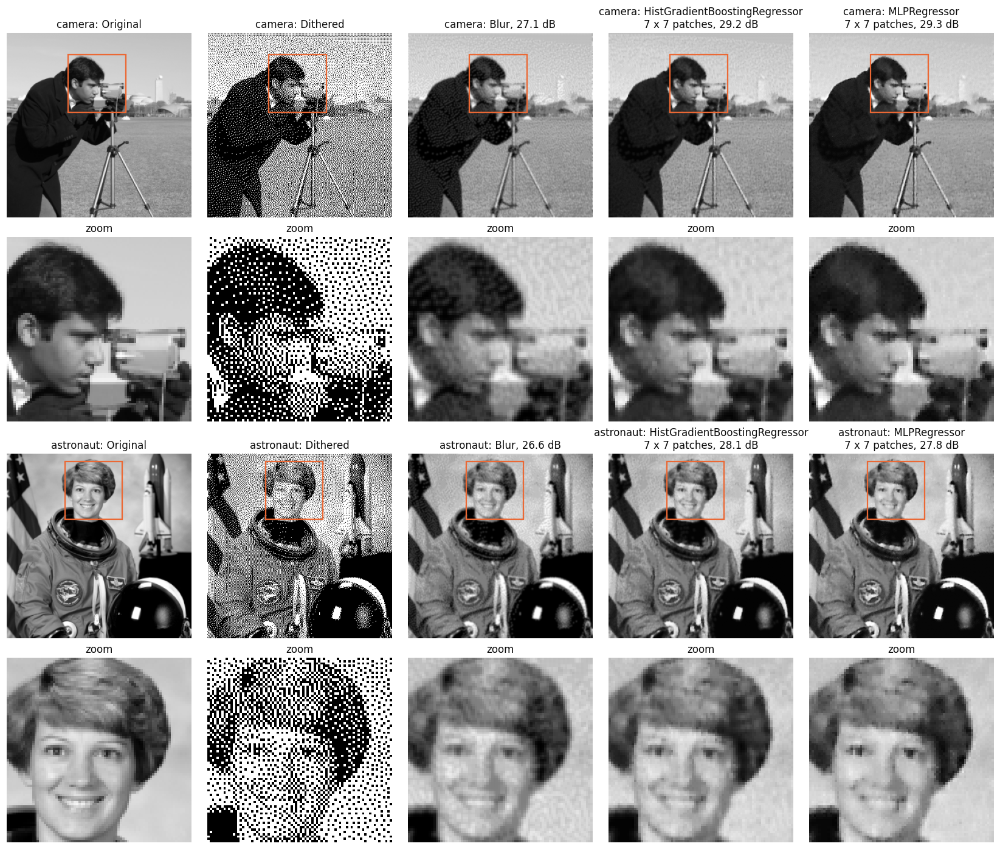

In [34]:
TEST_CROPS: dict[str, tuple[slice, slice]] = {  # (rows, columns) of each zoom region
    "camera": (slice(30, 110), slice(85, 165)),
    "astronaut": (slice(10, 90), slice(80, 160)),
}

mean_psnr: pd.Series = results[[f"{name} PSNR (dB)" for name in TEST_NAMES]].mean(
    axis=1
)
best_two: list[tuple[str, str]] = (
    mean_psnr.drop(index=(BLUR, NO_PATCH)).nlargest(n=2).index.tolist()
)

fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(15, 12.6), layout="constrained")
for test_index, name in enumerate(TEST_NAMES):
    rows, cols = TEST_CROPS[name]
    restored_panels: dict[str, FloatArray] = {"Blur": blurred[name]} | {
        f"{model_name}\n{patch} patches": restorations[(model_name, patch)][name]
        for model_name, patch in best_two
    }
    panels = {"Original": grays[name], "Dithered": dithers[name]} | {
        f"{title}, {psnr(reference=grays[name], estimate=picture):.1f} dB": picture
        for title, picture in restored_panels.items()
    }
    for column, (title, picture) in enumerate(panels.items()):
        full_ax, zoom_ax = axes[2 * test_index : 2 * test_index + 2, column]
        show_gray(ax=full_ax, picture=picture, title=f"{name}: {title}")
        outline(ax=full_ax, rows=rows, cols=cols)
        show_gray(ax=zoom_ax, picture=picture[rows, cols], title="zoom")
plt.show()

**Ridge 的係數就是一個濾波器**

Ridge 的預測是區塊裡每一格乘上一個係數再加總，和卷積做的事一樣。把係數排回 k × k 就能直接和高斯濾波器比。

我看到 Ridge 的濾波器左右、上下不對稱，猜和 dithering 的掃描方向有關。所以多做一組：把掃描方向反過來（由右到左、由下到上）做 dithering，再學一次。

7 x 7 Ridge coefficients: sum 1.000, smallest -0.008, center 0.153, left 0.112, right 0.086, above 0.122, below 0.091
7 x 7 Ridge coefficients, scan reversed: sum 0.999, smallest -0.008, center 0.153, left 0.084, right 0.113, above 0.091, below 0.122
11 x 11 Ridge coefficients: sum 0.997, smallest -0.008, center 0.153, left 0.113, right 0.087, above 0.122, below 0.092
11 x 11 Ridge coefficients, scan reversed: sum 0.996, smallest -0.009, center 0.153, left 0.085, right 0.114, above 0.091, below 0.122


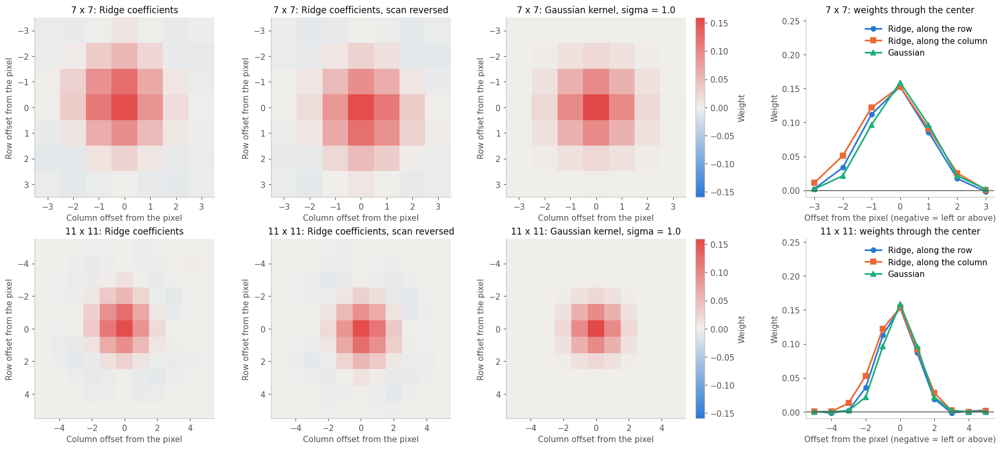

In [35]:
DIVERGING: LinearSegmentedColormap = LinearSegmentedColormap.from_list(
    name="blue_gray_red",
    colors=["#2a78d6", "#f0efec", "#e34948"],
)


def gaussian_kernel(size: int, sigma: float) -> FloatArray:
    """The size x size filter a Gaussian blur applies: the blur of one white pixel."""
    impulse: FloatArray = np.zeros(shape=(size, size))
    impulse[size // 2, size // 2] = 1.0
    return gaussian_filter(input=impulse, sigma=sigma, mode="constant")


# Dithering a flipped image and flipping the result back reverses both scan directions.
reversed_dithers: dict[str, FloatArray] = {
    name: np.flip(m=fs_dither(img=np.flip(m=grays[name]))) for name in TRAIN_NAMES
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(17, 7.6),
    layout="constrained",
    gridspec_kw={"wspace": 0.1},
)
for row_axes, size in zip(axes, PATCH_SIZES, strict=True):
    reversed_set: tuple[Features, FloatArray] = sample_patches(
        dithered=reversed_dithers,
        names=TRAIN_NAMES,
        size=size,
    )
    filters: dict[str, FloatArray] = {
        "Ridge coefficients": Ridge(alpha=1.0)
        .fit(X=train_sets[size][0], y=train_sets[size][1])
        .coef_.reshape(size, size),
        "Ridge coefficients, scan reversed": Ridge(alpha=1.0)
        .fit(X=reversed_set[0], y=reversed_set[1])
        .coef_.reshape(size, size),
        f"Gaussian kernel, sigma = {best_sigma}": gaussian_kernel(
            size=size,
            sigma=best_sigma,
        ),
    }
    offsets: IntArray = np.arange(size) - size // 2
    limit: float = max(float(np.abs(kernel).max()) for kernel in filters.values())
    for ax, (title, kernel) in zip(row_axes, filters.items(), strict=False):
        mesh = ax.imshow(
            X=kernel,
            cmap=DIVERGING,
            vmin=-limit,
            vmax=limit,
            extent=(
                offsets[0] - 0.5,
                offsets[-1] + 0.5,
                offsets[-1] + 0.5,
                offsets[0] - 0.5,
            ),
        )
        ax.set_title(label=f"{size} x {size}: {title}")
        ax.set_xlabel(xlabel="Column offset from the pixel")
        ax.set_ylabel(ylabel="Row offset from the pixel")
    fig.colorbar(mappable=mesh, ax=row_axes[2], label="Weight")

    profile_ax: Axes = row_axes[3]
    ridge_filter: FloatArray = filters["Ridge coefficients"]
    profiles: dict[str, FloatArray] = {
        "Ridge, along the row": ridge_filter[size // 2, :],
        "Ridge, along the column": ridge_filter[:, size // 2],
        "Gaussian": filters[f"Gaussian kernel, sigma = {best_sigma}"][size // 2, :],
    }
    for (label, profile), color, marker in zip(
        profiles.items(),
        SERIES_COLORS,
        "os^",
        strict=False,
    ):
        profile_ax.plot(
            offsets,
            profile,
            color=color,
            marker=marker,
            markersize=6,
            linewidth=2,
            label=label,
        )
    profile_ax.axhline(y=0, color=INK_SECONDARY, linewidth=1)
    profile_ax.set_title(label=f"{size} x {size}: weights through the center")
    profile_ax.set_xlabel(xlabel="Offset from the pixel (negative = left or above)")
    profile_ax.set_ylabel(ylabel="Weight")
    profile_ax.set_ylim(top=1.6 * limit)  # headroom for the legend
    profile_ax.legend(frameon=False, loc="upper right")

    center: int = size // 2
    for title, kernel in list(filters.items())[:2]:
        print(
            f"{size} x {size} {title}: sum {kernel.sum():.3f}, "
            f"smallest {kernel.min():.3f}, center {kernel[center, center]:.3f}, "
            f"left {kernel[center, center - 1]:.3f}, "
            f"right {kernel[center, center + 1]:.3f}, "
            f"above {kernel[center - 1, center]:.3f}, "
            f"below {kernel[center + 1, center]:.3f}"
        )
plt.show()

**學到的濾波器和高斯濾波器的差別**

- **相同**：權重加起來是 1.00，中心最重（0.15），往外變小。它也是在平均附近的白點。
- **有負值**：最外圈有很小的負權重，最小 −0.008。高斯濾波器全部是正的。
- **不對稱**：左邊 0.112、右邊 0.086，上面 0.122、下面 0.091。高斯濾波器四邊都是 0.097。

掃描方向反過來後，濾波器跟著反過來，變成右邊和下面比較重（第二欄）。影像沒有變，所以不對稱來自 dithering 的掃描順序，我的猜測成立。

至於為什麼偏向先掃到的那一側，我沒有想到確定的解釋。

### B6. 泛化能力

訓練影像換成只有紋理（brick、grass、gravel）或只有文字（page），一樣抽 60,000 個像素，用 7 × 7 區塊，再測 camera 和 astronaut。

我猜 `HistGradientBoostingRegressor` 掉最少，因為它在 B5 分數最高。`Ridge` 太簡單，應該掉最多。

In [36]:
TRAINING_GROUPS: dict[str, tuple[str, ...]] = {
    "All nine images": TRAIN_NAMES,
    "Textures only": ("brick", "grass", "gravel"),
    "Page only": ("page",),
}
GROUP_SIZE: int = 7  # patch size of the generalization test

group_models: dict[str, Regressor] = {}  # HistGradientBoosting trained on each group
group_rows: dict[str, dict[tuple[str, str], float]] = {
    model_name: {
        (test_name, "All nine images"): results.loc[
            (model_name, f"{GROUP_SIZE} x {GROUP_SIZE}"),
            f"{test_name} PSNR (dB)",
        ]
        for test_name in TEST_NAMES
    }
    for model_name in regressors()
}
group_models["All nine images"] = fitted[("HistGradientBoostingRegressor", GROUP_SIZE)]
for group, names in list(TRAINING_GROUPS.items())[1:]:
    group_set: tuple[Features, FloatArray] = sample_patches(
        dithered=dithers,
        names=names,
        size=GROUP_SIZE,
    )
    for model_name, model in regressors().items():
        group_scores, _ = fit_and_restore(
            model=model,
            train_set=group_set,
            size=GROUP_SIZE,
        )
        for test_name in TEST_NAMES:
            group_rows[model_name][(test_name, group)] = group_scores[
                f"{test_name} PSNR (dB)"
            ]
        if model_name == "HistGradientBoostingRegressor":
            group_models[group] = model

group_table: pd.DataFrame = (
    pd.DataFrame.from_dict(data=group_rows, orient="index")
    .rename_axis(index="Model")
    .reindex(
        columns=pd.MultiIndex.from_product(
            iterables=[TEST_NAMES, list(TRAINING_GROUPS)],
            names=["Test image", "Trained on"],
        ),
    )
)
display(
    group_table.style.set_caption(
        caption=f"Test PSNR (dB), {GROUP_SIZE} x {GROUP_SIZE} patches, {N_TRAIN:,} training pixels",
    ).format(precision=2),
)

結果和我猜的相反，越簡單的模型掉越少。

- **`Ridge` 掉最少**：只用紋理掉 0.2 到 0.8 dB，只用文字掉 1.0 到 1.4 dB。
- **`HistGradientBoostingRegressor` 和 `MLPRegressor`**：掉 1.4 到 3.9 dB。
- **`RandomForestRegressor` 和 `KNeighborsRegressor`**：掉 3.2 到 7.1 dB。

我想知道是哪裡變差。所以把測試像素依原本的灰階分成 10 段，看 `HistGradientBoostingRegressor` 在每一段的誤差。

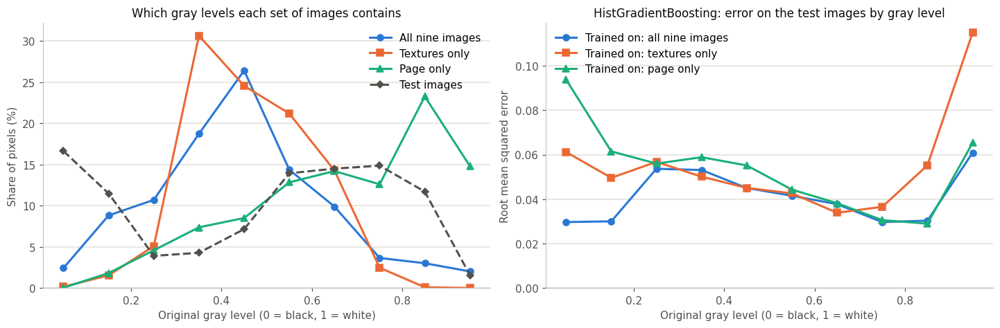

In [37]:
GRAY_BINS: NDArray[np.floating] = np.linspace(start=0.0, stop=1.0, num=11)
bin_centers: NDArray[np.floating] = (GRAY_BINS[:-1] + GRAY_BINS[1:]) / 2

test_grays: FloatArray = np.concatenate([grays[name].ravel() for name in TEST_NAMES])
test_patches: Features = np.concatenate(
    [test_features[GROUP_SIZE][name] for name in TEST_NAMES]
)
test_bin: IntArray = np.clip(
    np.digitize(x=test_grays, bins=GRAY_BINS) - 1,
    a_min=0,
    a_max=len(bin_centers) - 1,
)

fig, (share_ax, error_ax) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 4.2),
    layout="constrained",
)
for (group, names), color, marker in zip(
    TRAINING_GROUPS.items(),
    SERIES_COLORS,
    "os^",
    strict=False,
):
    group_grays: FloatArray = np.concatenate([grays[name].ravel() for name in names])
    share_ax.plot(
        bin_centers,
        100 * np.histogram(a=group_grays, bins=GRAY_BINS)[0] / len(group_grays),
        color=color,
        marker=marker,
        markersize=6,
        linewidth=2,
        label=group,
    )
    squared_error: FloatArray = (
        np.clip(group_models[group].predict(X=test_patches), a_min=0.0, a_max=1.0)
        - test_grays
    ) ** 2
    error_ax.plot(
        bin_centers,
        [
            np.sqrt(squared_error[test_bin == index].mean())
            for index in range(len(bin_centers))
        ],
        color=color,
        marker=marker,
        markersize=6,
        linewidth=2,
        label=f"Trained on: {group.lower()}",
    )
share_ax.plot(
    bin_centers,
    100 * np.histogram(a=test_grays, bins=GRAY_BINS)[0] / len(test_grays),
    color=INK_SECONDARY,
    linestyle="--",
    marker="D",
    markersize=5,
    linewidth=2,
    label="Test images",
)
share_ax.set_title(label="Which gray levels each set of images contains")
share_ax.set_ylabel(ylabel="Share of pixels (%)")
error_ax.set_title(label="HistGradientBoosting: error on the test images by gray level")
error_ax.set_ylabel(ylabel="Root mean squared error")
for ax in (share_ax, error_ax):
    ax.set_xlabel(xlabel="Original gray level (0 = black, 1 = white)")
    ax.set_ylim(bottom=0)
    ax.grid(visible=True, axis="y")
    ax.legend(frameon=False)
plt.show()

誤差變大的地方，就是訓練影像缺少的灰階。

- **只用紋理**：紋理影像幾乎沒有比 0.8 亮的像素，模型在最亮那段誤差最大。
- **只用文字**：文字影像比 0.2 暗的像素不到 2%，模型在最暗那段誤差最大。
- **影響很大的原因**：測試影像有 17% 的像素比 0.1 暗。

**模型學到的是內容還是 dithering 的過程：兩者都有，比例看模型**

`Ridge` 學到的幾乎只有過程：數附近有多少白點。這個規則和影像內容無關，所以換訓練影像影響很小。

彈性大的模型還多學了訓練影像常見的灰階和圖案。碰到訓練時很少看到的內容，就預測不準。

**回頭實測 B2 說的事：在訓練像素上測試會高估多少**

同樣是 9 張訓練影像，比較訓練時用過的 60,000 個像素，和同幾張圖裡沒用過的 60,000 個像素。

In [38]:
seen_set: tuple[Features, FloatArray] = train_sets[GROUP_SIZE]
unseen_set: tuple[Features, FloatArray] = sample_patches(
    dithered=dithers,
    names=TRAIN_NAMES,
    size=GROUP_SIZE,
    skip=N_TRAIN,
)
display(
    pd.DataFrame.from_dict(
        data={
            model_name: {
                column_name: psnr(
                    reference=targets,
                    estimate=np.clip(
                        fitted[(model_name, GROUP_SIZE)].predict(X=features),
                        a_min=0.0,
                        a_max=1.0,
                    ),
                )
                for column_name, (features, targets) in {
                    "Pixels it was trained on (dB)": seen_set,
                    "Other pixels of the same images (dB)": unseen_set,
                }.items()
            }
            for model_name in regressors()
        },
        orient="index",
    )
    .rename_axis(index="Model")
    .assign(**{"Gap (dB)": lambda table: table.iloc[:, 0] - table.iloc[:, 1]})
    .style.set_caption(
        caption=f"PSNR on the nine training images, {GROUP_SIZE} x {GROUP_SIZE} patches",
    )
    .format(precision=2),
)

,Pixels it was trained on (dB),Other pixels of the same images (dB),Gap (dB)
Model,,,
Ridge,26.61,26.72,-0.10
KNeighborsRegressor,24.39,22.53,1.86
RandomForestRegressor,30.83,27.41,3.42
HistGradientBoostingRegressor,28.31,27.55,0.76
MLPRegressor,28.14,27.47,0.67


`RandomForestRegressor` 在看過的像素上高出 3.4 dB，`KNeighborsRegressor` 高出 1.9 dB，這兩種模型會把訓練樣本記下來。`Ridge` 只有 49 個係數，記不住，兩邊幾乎一樣。

排名也被扭曲。在看過的像素上 `RandomForestRegressor` 是第一名，換成沒看過的像素只排第三。

### B7. 討論

作業提示要想想高維二值向量之間的距離，所以先量一次。兩個區塊的距離就是有幾格黑白不同。

從測試影像抽 5,000 個區塊，各自在 60,000 個訓練區塊裡找最像的那一個，數它們有幾格不同。

In [39]:
N_QUERY: int = 5_000

query_rng: np.random.Generator = np.random.default_rng(seed=SEED)
distance_rows: dict[str, dict[str, float]] = {}
for size in PATCH_SIZES:
    train_patches: Features = train_sets[size][0]
    all_test_patches: Features = np.concatenate(
        [test_features[size][name] for name in TEST_NAMES]
    )
    query: Features = query_rng.choice(a=all_test_patches, size=N_QUERY, replace=False)
    # For black-and-white patches the squared Euclidean distance counts differing cells.
    _, nearest_distance = pairwise_distances_argmin_min(X=query, Y=train_patches)
    cells_to_nearest: FloatArray = nearest_distance**2
    cells_between_random: FloatArray = np.abs(
        train_patches[:N_QUERY] - train_patches[N_QUERY : 2 * N_QUERY]
    ).sum(axis=1)
    distance_rows[f"{size} x {size}"] = {
        "Cells per patch": size * size,
        "Possible patches": float(2) ** (size * size),
        "Differing cells to the nearest training patch (mean)": float(
            cells_to_nearest.mean()
        ),
        "Test patches with an identical training patch (%)": float(
            100 * np.mean(cells_to_nearest < 0.5)
        ),
        "Differing cells between two random patches (mean)": float(
            cells_between_random.mean()
        ),
    }

display(
    pd.DataFrame.from_dict(data=distance_rows, orient="index")
    .rename_axis(index="Patch size")
    .style.set_caption(
        caption=f"{N_QUERY:,} test patches against the {N_TRAIN:,} training patches",
    )
    .format(
        formatter={
            "Cells per patch": "{:.0f}",
            "Possible patches": "{:.1e}",
            "Differing cells to the nearest training patch (mean)": "{:.1f}",
            "Test patches with an identical training patch (%)": "{:.1f}",
            "Differing cells between two random patches (mean)": "{:.1f}",
        },
    ),
)

,Cells per patch,Possible patches,Differing cells to the nearest training patch (mean),Test patches with an identical training patch (%),Differing cells between two random patches (mean)
Patch size,,,,,
7 x 7,49,5.6e+14,4.6,9.2,24.3
11 x 11,121,2.7e+36,21.6,0.0,59.8


**最好的模型：`HistGradientBoostingRegressor` 搭配 7 × 7 區塊**

camera 是 29.20 dB，astronaut 是 28.13 dB，比模糊 baseline（27.12 和 26.62 dB）高 2.1 和 1.5 dB。`MLPRegressor` 幾乎一樣好，camera 還略高（29.30 dB）。

從 B5 的放大圖看，模糊後的臉上還留著顆粒，這兩個模型的顆粒比較少。

**區塊加大沒有幫助，我在 B5 猜錯了**

`Ridge` 幾乎不變，其他模型都變差一點。`Ridge` 的係數圖說明了原因：有用的權重集中在中心 5 × 5，外圈接近 0。多出來的 72 格幾乎沒有新資訊，卻增加了要學的東西。

**最差的模型：`KNeighborsRegressor`**

7 × 7 是 23.50 和 22.39 dB，11 × 11 掉到 20.69 和 19.14 dB，都比模糊還差。它也是預測最慢的模型，因為每個像素都要和 60,000 個訓練區塊比一次。

原因在上表。7 × 7 的區塊有 $2^{49}$ 種可能，約 $5.6 \times 10^{14}$ 種，60,000 個訓練區塊只佔極小一部分。測試區塊只有 9.2% 找得到一模一樣的訓練區塊，最像的那個平均也差 4.6 格。

11 × 11 更嚴重。最像的訓練區塊平均差 21.6 格，隨機挑兩個區塊也才差 59.8 格，所謂的最近鄰居其實不怎麼像。

距離也只數有幾格不同，不管是哪幾格。`Ridge` 的係數圖顯示中心幾格最重要，`KNeighborsRegressor` 卻把每一格看得一樣重。